# temperature (meteo) : extraction et prevision

In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.tsatools import detrend
from statsmodels.tsa.seasonal import MSTL

import sys
sys.path.append("..")
from adapt_utils import sliding_window, predict, courbe_apprentissage, courbe_melange, comparer_adapt, barres_adapt

In [98]:
city = "Vancouver"

df = pd.read_csv("../../data/meteo/temperature.csv", parse_dates=["datetime"])
serie = df.set_index("datetime")[city] - 273.15
serie = serie.interpolate(limit_area="inside").dropna().loc[:pd.Timestamp("2017-10-28 00:00")]

temp = serie.to_numpy()
print(len(temp), "points de", serie.index[0], "a", serie.index[-1])
print("min/moy/max :", round(temp.min(), 1), round(temp.mean(), 1), round(temp.max(), 1))

44460 points de 2012-10-01 13:00:00 a 2017-10-28 00:00:00
min/moy/max : -28.0 10.7 33.9


## 1. visualisation

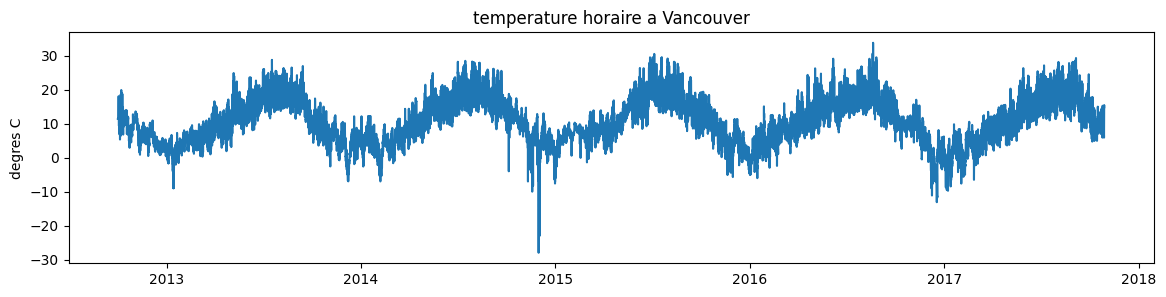

In [99]:
plt.figure(figsize=(14, 3))
plt.plot(serie)
plt.title(f"temperature horaire a {city}")
plt.ylabel("degres C")
plt.show()

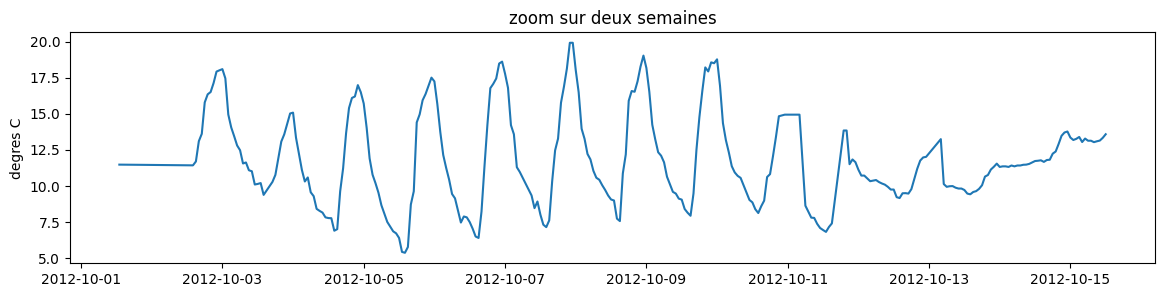

In [100]:
plt.figure(figsize=(14, 3))
plt.plot(serie.iloc[:24 * 14])
plt.title("zoom sur deux semaines")
plt.ylabel("degres C")
plt.show()

## 2. tendance (detrend)

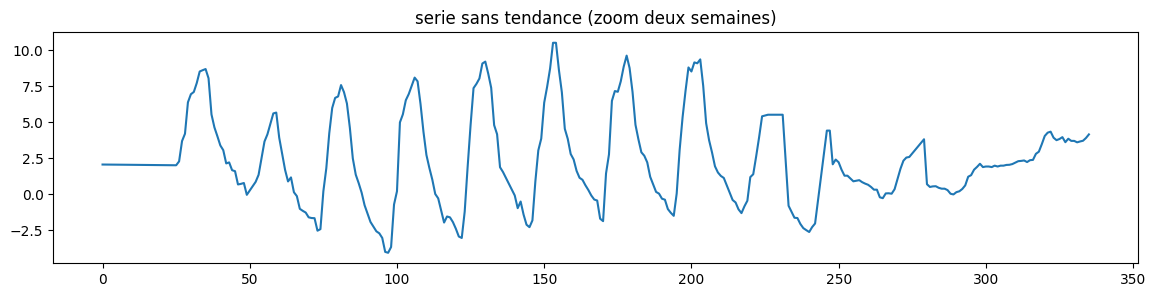

In [101]:
temp_sans_tendance = detrend(temp, order=1)

plt.figure(figsize=(14, 3))
plt.plot(temp_sans_tendance[:24 * 14])
plt.title("serie sans tendance (zoom deux semaines)")
plt.show()

## 3. periode (ACF)

on calcule l'ACF sur le signal detendance

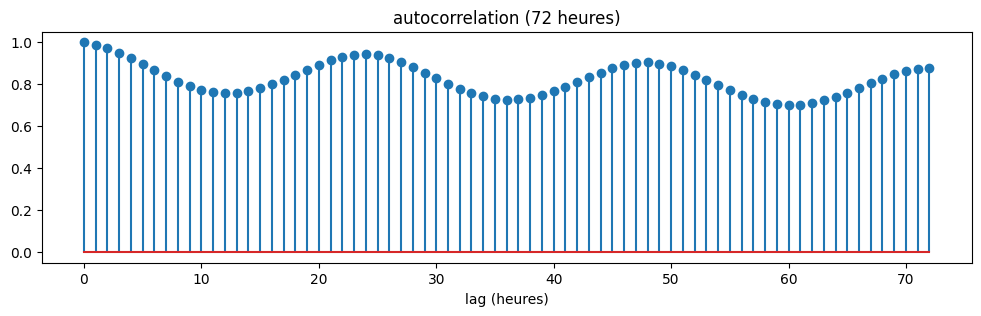

In [102]:
acf_values = acf(temp_sans_tendance, nlags=72)

plt.figure(figsize=(12, 3))
plt.stem(acf_values)
plt.title("autocorrelation (72 heures)")
plt.xlabel("lag (heures)")
plt.show()

## 4. periodogramme

In [103]:
f, power = periodogram(temp_sans_tendance)
periodes = 1 / f[1:]
puissance = power[1:]

ordre = np.argsort(puissance)[::-1]
periodes_detectees = []
for i in ordre:
    p = periodes[i]
    if all(not (0.6 < p / autre < 1.6) for autre in periodes_detectees):
        periodes_detectees.append(p)
    if len(periodes_detectees) == 2:
        break
periodes_detectees = sorted(int(round(p)) for p in periodes_detectees)
print("periodes detectees :", periodes_detectees, "heures")

periodes detectees : [24, 8892] heures


## 5. extraction (STL)

In [104]:
from series_utils import estimate_period

from scipy.signal import find_peaks
from statsmodels.tsa.seasonal import STL

#affichage de la période, de la pente, de l'amplitude et du bruit
period = estimate_period(temp)
res = STL(temp, period=period, robust=True).fit()
pente=np.polyfit(np.arange(len(temp)), res.trend, 1)[0]
amplitude = (res.seasonal.max() - res.seasonal.min()) / 2
bruit = np.nanstd(res.resid)
print(f"periode : {period} heures, pente : {pente:.3f}, amplitude : {amplitude:.3f}, bruit : {bruit:.3f}")

periode : 24 heures, pente : 0.000, amplitude : 15.173, bruit : 1.229


## 6. extraction rapide : cycle journalier (STL)


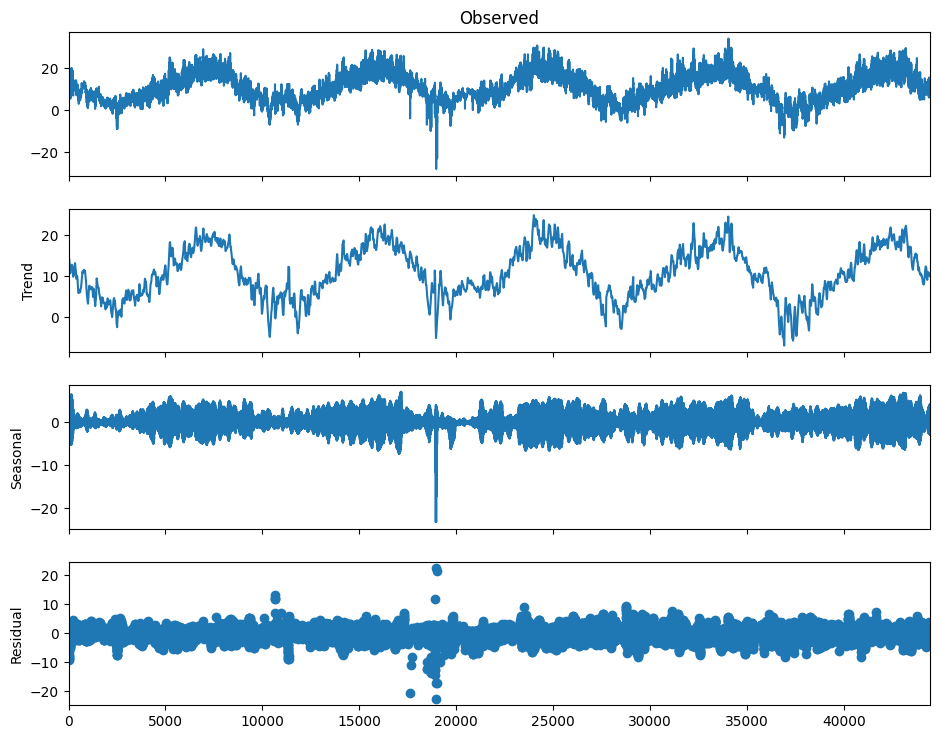

In [105]:
periode_jour = periodes_detectees[0]
res_stl = STL(temp, period=periode_jour, robust=True).fit()

fig = res_stl.plot()
fig.set_size_inches(10, 8)
plt.show()

## 7. prevision : villes source vers ville cible

In [106]:
fin_commune = pd.Timestamp("2017-10-28 00:00")

def temperature_ville(ville):
    s = df.set_index("datetime")[ville] - 273.15
    return s.interpolate(limit_area="inside").dropna().loc[:fin_commune].to_numpy()

def serie_centree(ville, ratio=0.8):
    x = temperature_ville(ville)
    return x - x[:int(len(x) * ratio)].mean()

source_villes = ["Seattle", "Portland", "San Francisco", "Los Angeles"]
ville_cible = "Miami"
window_size = 24
horizon = 24

Xs_train_list, ys_train_list, Xs_test_list, ys_test_list = [], [], [], []
for v in source_villes:
    X, y = sliding_window(serie_centree(v), window_size, horizon)
    s = int(len(X) * 0.8)
    Xs_train_list.append(X[:s]); ys_train_list.append(y[:s])
    Xs_test_list.append(X[s:]); ys_test_list.append(y[s:])
Xs_train = np.vstack(Xs_train_list); ys_train = np.concatenate(ys_train_list)
Xs_test = np.vstack(Xs_test_list); ys_test = np.concatenate(ys_test_list)

Xc, yc = sliding_window(serie_centree(ville_cible), window_size, horizon)
split_c = int(len(Xc) * 0.8)
Xc_train, yc_train, Xc_test, yc_test = Xc[:split_c], yc[:split_c], Xc[split_c:], yc[split_c:]

r_source_source = predict("forecast", Xs_train, ys_train, Xs_test, ys_test)
r_source_cible = predict("forecast", Xs_train, ys_train, Xc_test, yc_test)
print("source -> source :", {k: round(v, 3) for k, v in r_source_source.items()})
print("source -> cible  :", {k: round(v, 3) for k, v in r_source_cible.items()})

source -> source : {'mse': 6.541, 'r2': 0.857}
source -> cible  : {'mse': 4.319, 'r2': 0.73}


## 8. combien de donnees cible pour un bon modele

on part du modele entraine sur la source seule, et on ajoute des donnees cible a l'entrainement, en mesurant le R2 sur le test cible.

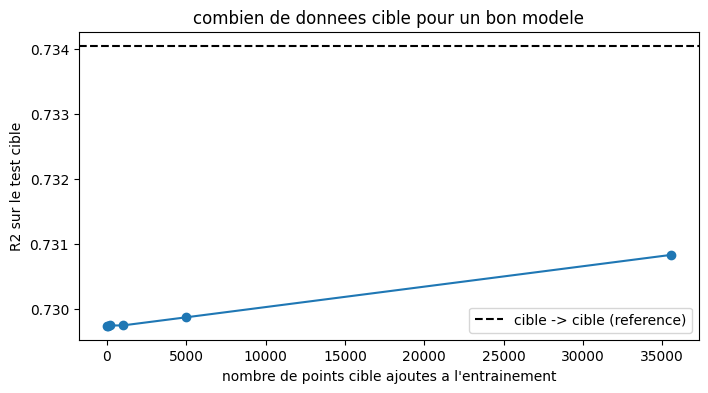

In [107]:
r_cible_ref = predict("forecast", Xc_train, yc_train, Xc_test, yc_test)

n_values = [0, 50, 200, 1000, 5000, len(Xc_train)]
r2_courbe = []
for n in n_values:
    if n == 0:
        X_train, y_train = Xs_train, ys_train
    else:
        X_train = np.vstack([Xs_train, Xc_train[:n]])
        y_train = np.concatenate([ys_train, yc_train[:n]])
    r2_courbe.append(predict("forecast", X_train, y_train, Xc_test, yc_test)["r2"])

plt.figure(figsize=(8, 4))
plt.plot(n_values, r2_courbe, marker="o")
plt.axhline(r_cible_ref["r2"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("R2 sur le test cible")
plt.title("combien de donnees cible pour un bon modele")
plt.legend()
plt.show()

## 9. courbes d'apprentissage separees : serie brute (source et cible)

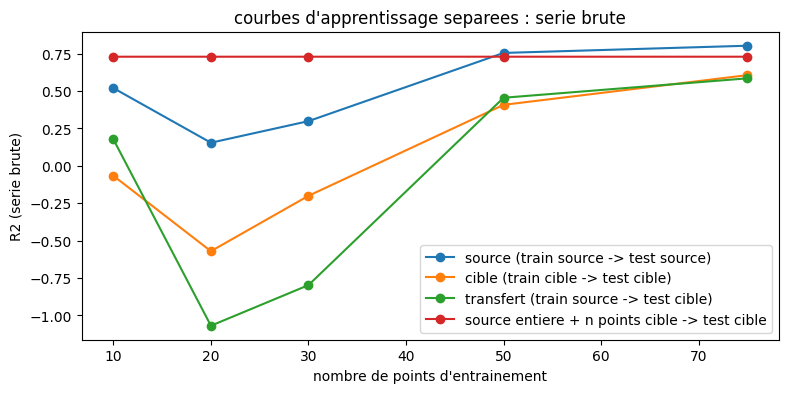

In [108]:
n_values = [10, 20, 30, 50, 75]
ns_source, r2_source = courbe_apprentissage(Xs_train, ys_train, Xs_test, ys_test, "forecast", n_values)
ns_cible, r2_cible = courbe_apprentissage(Xc_train, yc_train, Xc_test, yc_test, "forecast", n_values)

ns_transfert, r2_transfert = courbe_apprentissage(Xs_train, ys_train, Xc_test, yc_test, "forecast", n_values)

ns_melange, r2_melange = courbe_melange(Xs_train, ys_train, Xc_train, yc_train, Xc_test, yc_test, "forecast", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, r2_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, r2_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, r2_transfert, marker="o", label="transfert (train source -> test cible)")
plt.plot(ns_melange, r2_melange, marker="o", label="source entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("R2 (serie brute)")
plt.title("courbes d'apprentissage separees : serie brute")
plt.legend()
plt.show()

## 10. prevision de la serie desaisonnalisee (T+N, MSTL)

In [109]:
sigma_bruit = {}
sigma_test = {}
series_TN_fuite = {}
moyenne_ville = {}
n_annee = 8760

def serie_TN(ville, ratio=0.8):
    temp = temperature_ville(ville)
    n_app = int(len(temp) * ratio)
    res = MSTL(temp[:n_app], periods=(24, 8766), stl_kwargs=dict(seasonal_jump=24, trend_jump=24, low_pass_jump=24)).fit()
    sigma_bruit[ville] = np.nanstd(res.resid)
    sais_app = np.asarray(res.seasonal).sum(axis=1)
    n_test = len(temp) - n_app
    n_blocs = n_app // n_annee
    blocs = np.stack([sais_app[n_app - (k + 1) * n_annee: n_app - k * n_annee] for k in range(n_blocs)])
    prolonge = np.tile(blocs.mean(axis=0), n_test // n_annee + 1)[:n_test]

    res_tout = MSTL(temp, periods=(24, 8766), stl_kwargs=dict(seasonal_jump=24, trend_jump=24, low_pass_jump=24)).fit()
    sigma_test[ville] = np.nanstd(np.asarray(res_tout.resid)[n_app:])
    series_TN_fuite[ville] = temp - np.asarray(res_tout.seasonal).sum(axis=1)

    z = temp - np.concatenate([sais_app, prolonge])
    moyenne_ville[ville] = float(z[:n_app].mean())
    series_TN_fuite[ville] = series_TN_fuite[ville] - moyenne_ville[ville]
    return z - moyenne_ville[ville]

horizon_residu = 24

series_TN = {}
Xrs_tr_list, yrs_tr_list, Xrs_te_list, yrs_te_list = [], [], [], []
for v in source_villes:
    series_TN[v] = serie_TN(v)
    X, y = sliding_window(series_TN[v], window_size, horizon_residu)
    s = int(len(X) * 0.8)
    Xrs_tr_list.append(X[:s]); yrs_tr_list.append(y[:s])
    Xrs_te_list.append(X[s:]); yrs_te_list.append(y[s:])
Xrs_train = np.vstack(Xrs_tr_list); yrs_train = np.concatenate(yrs_tr_list)
Xrs_test = np.vstack(Xrs_te_list); yrs_test = np.concatenate(yrs_te_list)

series_TN[ville_cible] = serie_TN(ville_cible)
Xrc, yrc = sliding_window(series_TN[ville_cible], window_size, horizon_residu)
split_rc = int(len(Xrc) * 0.8)
Xrc_train, yrc_train, Xrc_test, yrc_test = Xrc[:split_rc], yrc[:split_rc], Xrc[split_rc:], yrc[split_rc:]

r_res_ss = predict("forecast", Xrs_train, yrs_train, Xrs_test, yrs_test)
r_res_sc = predict("forecast", Xrs_train, yrs_train, Xrc_test, yrc_test)
print("T+N source -> source :", {k: round(v, 3) for k, v in r_res_ss.items()})
print("T+N source -> cible  :", {k: round(v, 3) for k, v in r_res_sc.items()})
print("moyenne retiree par ville :", {v: round(x, 2) for v, x in moyenne_ville.items()})
print("sigma du train :", {v: round(float(x), 3) for v, x in sigma_bruit.items()})
print("sigma du test  :", {v: round(float(x), 3) for v, x in sigma_test.items()})


T+N source -> source : {'mse': 6.997, 'r2': 0.485}
T+N source -> cible  : {'mse': 4.596, 'r2': 0.284}
moyenne retiree par ville : {'Seattle': 11.44, 'Portland': 11.87, 'San Francisco': 14.79, 'Los Angeles': 17.38, 'Miami': 24.87}
sigma du train : {'Seattle': 2.25, 'Portland': 2.713, 'San Francisco': 1.98, 'Los Angeles': 2.381, 'Miami': 1.769}
sigma du test  : {'Seattle': 1.999, 'Portland': 2.283, 'San Francisco': 1.752, 'Los Angeles': 2.193, 'Miami': 1.59}


## 11. serie desaisonnalisee (T+N) : combien de donnees cible pour un bon modele


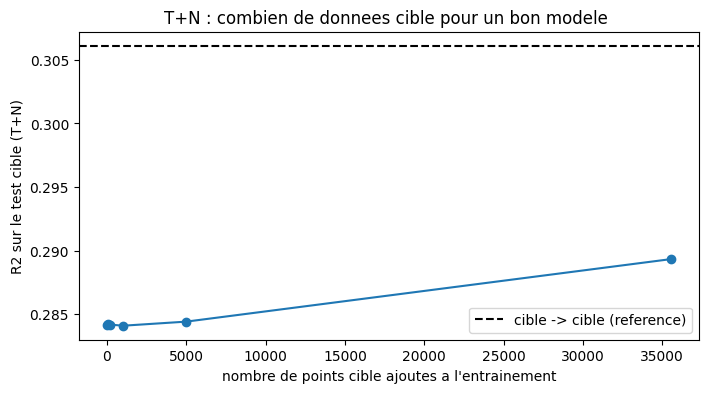

In [110]:
r_res_ref = predict("forecast", Xrc_train, yrc_train, Xrc_test, yrc_test)

n_values_r = [0, 50, 200, 1000, 5000, len(Xrc_train)]
r2_courbe_r = []
for n in n_values_r:
    if n == 0:
        X_train, y_train = Xrs_train, yrs_train
    else:
        X_train = np.vstack([Xrs_train, Xrc_train[:n]])
        y_train = np.concatenate([yrs_train, yrc_train[:n]])
    r2_courbe_r.append(predict("forecast", X_train, y_train, Xrc_test, yrc_test)["r2"])

plt.figure(figsize=(8, 4))
plt.plot(n_values_r, r2_courbe_r, marker="o")
plt.axhline(r_res_ref["r2"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("R2 sur le test cible (T+N)")
plt.title("T+N : combien de donnees cible pour un bon modele ")
plt.legend()
plt.show()

## 12. courbes d'apprentissage separees : T+N (source et cible)


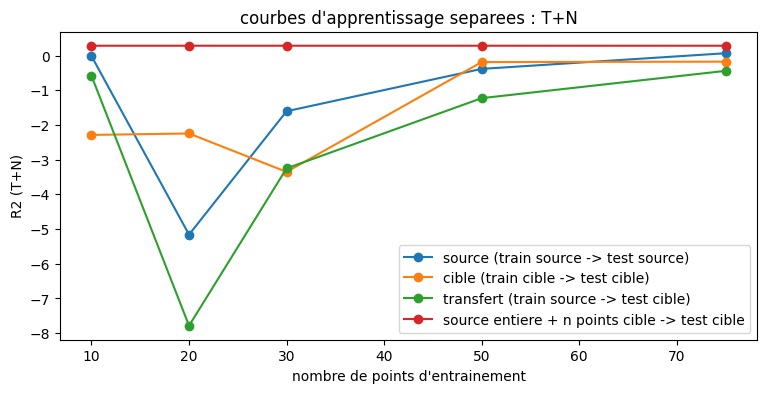

In [111]:
ns_source, r2_source = courbe_apprentissage(Xrs_train, yrs_train, Xrs_test, yrs_test, "forecast", n_values)
ns_cible, r2_cible = courbe_apprentissage(Xrc_train, yrc_train, Xrc_test, yrc_test, "forecast", n_values)

ns_transfert, r2_transfert = courbe_apprentissage(Xrs_train, yrs_train, Xrc_test, yrc_test, "forecast", n_values)

ns_melange, r2_melange = courbe_melange(Xrs_train, yrs_train, Xrc_train, yrc_train, Xrc_test, yrc_test, "forecast", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, r2_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, r2_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, r2_transfert, marker="o", label="transfert (train source -> test cible)")
plt.plot(ns_melange, r2_melange, marker="o", label="source entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("R2 (T+N)")
plt.title("courbes d'apprentissage separees : T+N")
plt.legend()
plt.show()

## 13. performances par ville source

deux facons de mesurer la performance par ville. d'abord un seul modele partage, entraine sur toutes les villes source a la fois puis evalue ville par ville : cela mesure ce que vaut un modele commun. ensuite un modele propre a chaque ville, entraine et teste sur la meme ville seule.

temperature brute (modele partage) : R2 par ville source
  Seattle : 0.863
  Portland : 0.865
  San Francisco : 0.835
  Los Angeles : 0.853
cible (Miami) : 0.73


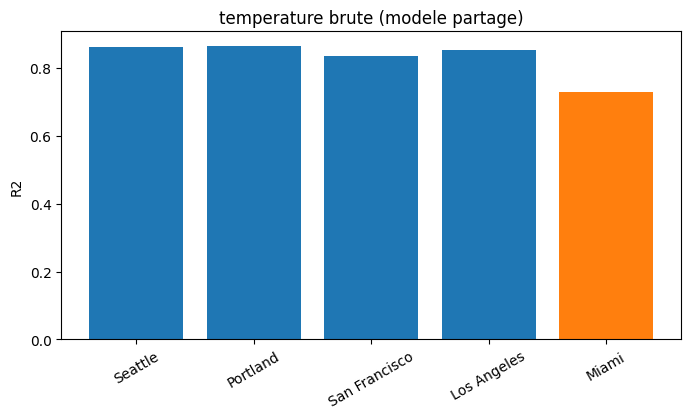

In [112]:
def barres_par_ville(X_train, y_train, test_X_list, test_y_list, X_cible, y_cible, titre):
    valeurs = []
    print(titre, ": R2 par ville source")
    for k, ville in enumerate(source_villes):
        r2 = predict("forecast", X_train, y_train, test_X_list[k], test_y_list[k])["r2"]
        valeurs.append(r2)
        print(f"  {ville} : {round(r2, 3)}")
    r2_cible = predict("forecast", X_train, y_train, X_cible, y_cible)["r2"]
    print(f"cible ({ville_cible}) : {round(r2_cible, 3)}")

    noms = source_villes + [ville_cible]
    couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
    plt.figure(figsize=(8, 4))
    plt.bar(noms, valeurs + [r2_cible], color=couleurs)
    plt.ylabel("R2")
    plt.title(titre)
    plt.xticks(rotation=30)
    plt.show()

barres_par_ville(Xs_train, ys_train, Xs_test_list, ys_test_list, Xc_test, yc_test, "temperature brute (modele partage)")

serie T+N (modele partage) : R2 par ville source
  Seattle : 0.442
  Portland : 0.429
  San Francisco : 0.501
  Los Angeles : 0.536
cible (Miami) : 0.284


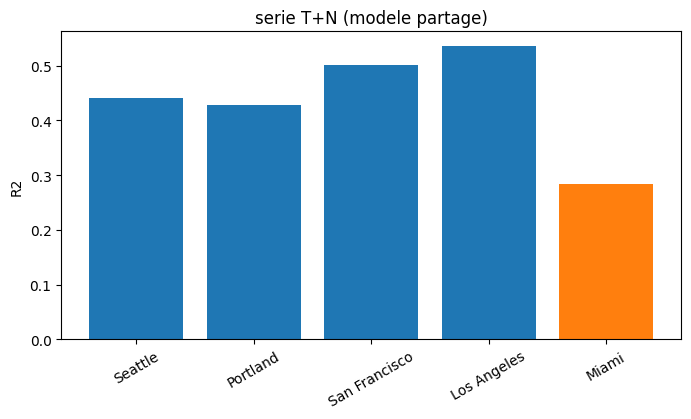

In [113]:
barres_par_ville(Xrs_train, yrs_train, Xrs_te_list, yrs_te_list, Xrc_test, yrc_test, "serie T+N (modele partage)")

temperature brute (un modele par ville) : R2 par ville (un modele par ville)
  Seattle : 0.864
  Portland : 0.865
  San Francisco : 0.834
  Los Angeles : 0.854
cible (Miami) : 0.734


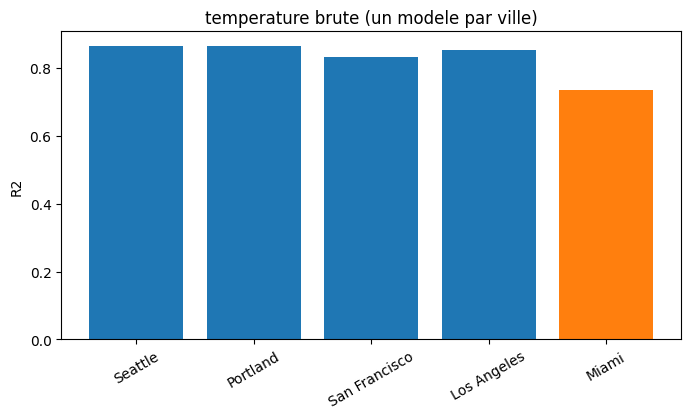

In [114]:
def barres_par_ville_propre(train_X, train_y, test_X, test_y, Xc_tr, yc_tr, Xc_te, yc_te, titre):
    valeurs = []
    print(titre, ": R2 par ville (un modele par ville)")
    for k, ville in enumerate(source_villes):
        r2 = predict("forecast", train_X[k], train_y[k], test_X[k], test_y[k])["r2"]
        valeurs.append(r2)
        print(f"  {ville} : {round(r2, 3)}")
    r2_cible = predict("forecast", Xc_tr, yc_tr, Xc_te, yc_te)["r2"]
    print(f"cible ({ville_cible}) : {round(r2_cible, 3)}")

    noms = source_villes + [ville_cible]
    couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
    plt.figure(figsize=(8, 4))
    plt.bar(noms, valeurs + [r2_cible], color=couleurs)
    plt.ylabel("R2")
    plt.title(titre)
    plt.xticks(rotation=30)
    plt.show()

barres_par_ville_propre(Xs_train_list, ys_train_list, Xs_test_list, ys_test_list, Xc_train, yc_train, Xc_test, yc_test, "temperature brute (un modele par ville)")

serie T+N (un modele par ville) : R2 par ville (un modele par ville)
  Seattle : 0.445
  Portland : 0.432
  San Francisco : 0.491
  Los Angeles : 0.534
cible (Miami) : 0.306


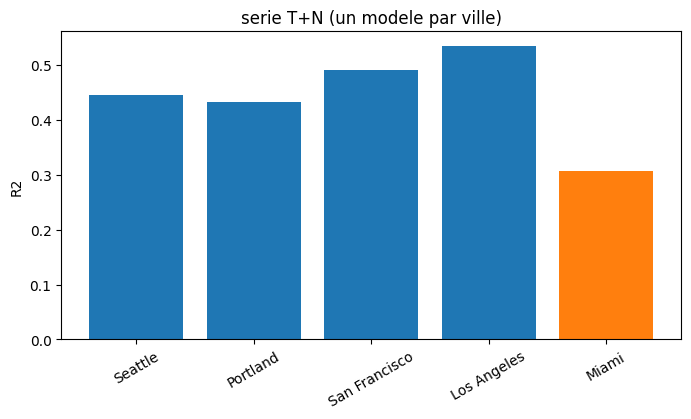

In [115]:
barres_par_ville_propre(Xrs_tr_list, yrs_tr_list, Xrs_te_list, yrs_te_list, Xrc_train, yrc_train, Xrc_test, yrc_test, "serie T+N (un modele par ville)")

## 14. normalisation par le bruit

le R2 par ville depend de la variance totale du domaine, qui differe (Jerusalem varie peu, donc son R2 s'effondre). pour comparer equitablement les villes, on rapporte l'erreur au niveau de bruit propre a chaque domaine : RMSE / sigma.

RMSE / sigma_test par ville (T+N) :
  Seattle : 1.32
  Portland : 1.33
  San Francisco : 1.37
  Los Angeles : 1.12
  cible (Miami) : 1.35


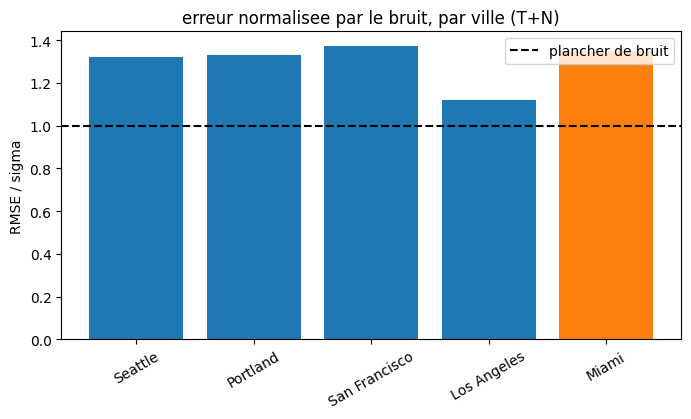

In [116]:
normes = []
print("RMSE / sigma_test par ville (T+N) :")
for k, ville in enumerate(source_villes):
    mse = predict("forecast", Xrs_train, yrs_train, Xrs_te_list[k], yrs_te_list[k])["mse"]
    n = np.sqrt(mse) / sigma_test[ville]
    normes.append(n)
    print(f"  {ville} : {round(n, 2)}")
mse_cible = predict("forecast", Xrs_train, yrs_train, Xrc_test, yrc_test)["mse"]
norme_cible = np.sqrt(mse_cible) / sigma_test[ville_cible]
print(f"  cible ({ville_cible}) : {round(norme_cible, 2)}")

noms = source_villes + [ville_cible]
couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
plt.figure(figsize=(8, 4))
plt.bar(noms, normes + [norme_cible], color=couleurs)
plt.axhline(1.0, color="k", linestyle="--", label="plancher de bruit")
plt.ylabel("RMSE / sigma")
plt.title("erreur normalisee par le bruit, par ville (T+N)")
plt.xticks(rotation=30)
plt.legend()
plt.show()

## 15. normalisation par le bruit : un modele par ville

RMSE / sigma_test par ville (T+N, un modele par ville) :
  Seattle : 1.32
  Portland : 1.33
  San Francisco : 1.39
  Los Angeles : 1.12
  cible (Miami) : 1.33


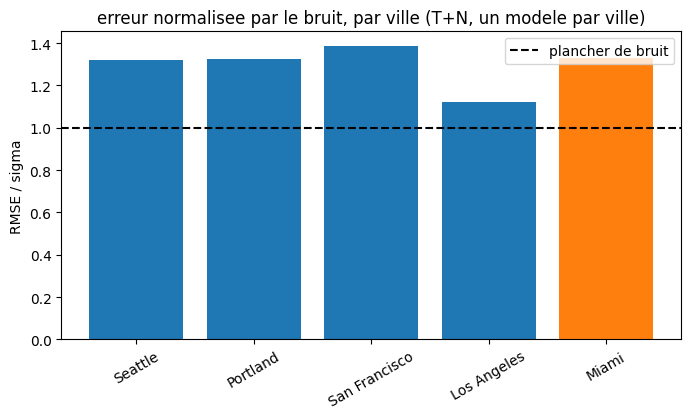

In [117]:
normes_propre = []
print("RMSE / sigma_test par ville (T+N, un modele par ville) :")
for k, ville in enumerate(source_villes):
    mse = predict("forecast", Xrs_tr_list[k], yrs_tr_list[k], Xrs_te_list[k], yrs_te_list[k])["mse"]
    n = np.sqrt(mse) / sigma_test[ville]
    normes_propre.append(n)
    print(f"  {ville} : {round(n, 2)}")
mse_cible = predict("forecast", Xrc_train, yrc_train, Xrc_test, yrc_test)["mse"]
norme_cible_propre = np.sqrt(mse_cible) / sigma_test[ville_cible]
print(f"  cible ({ville_cible}) : {round(norme_cible_propre, 2)}")

noms = source_villes + [ville_cible]
couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
plt.figure(figsize=(8, 4))
plt.bar(noms, normes_propre + [norme_cible_propre], color=couleurs)
plt.axhline(1.0, color="k", linestyle="--", label="plancher de bruit")
plt.ylabel("RMSE / sigma")
plt.title("erreur normalisee par le bruit, par ville (T+N, un modele par ville)")
plt.xticks(rotation=30)
plt.legend()
plt.show()

## 16. ADAPT


feature_based,CORAL

instance_based, KMM

parameter_based,  RegularTransferLR

temperature brute
  sans adaptation                  0.73
  CORAL (feature)                  0.425
  KMM (instance)                   0.712
  RegularTransferLR (parametre)    0.734
  cible -> cible                   0.734


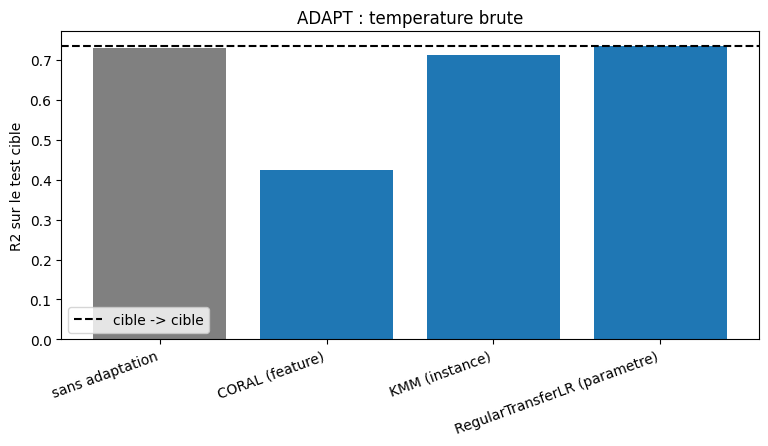

In [118]:
print("temperature brute")
res_adapt_brute = comparer_adapt("forecast", Xs_train, ys_train, Xc_train, yc_train, Xc_test, yc_test)
for k, v in res_adapt_brute.items():
    print(f"  {k:32s} {round(v, 3)}")

barres_adapt(res_adapt_brute, "ADAPT : temperature brute", "R2 sur le test cible")

serie T+N
  sans adaptation                  0.284
  CORAL (feature)                  0.156
  KMM (instance)                   0.276
  RegularTransferLR (parametre)    0.306
  cible -> cible                   0.306


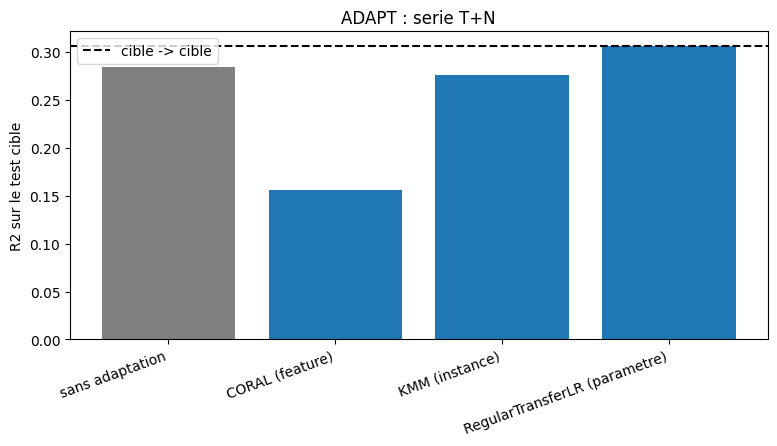

In [119]:
print("serie T+N")
res_adapt_tn = comparer_adapt("forecast", Xrs_train, yrs_train, Xrc_train, yrc_train, Xrc_test, yrc_test)
for k, v in res_adapt_tn.items():
    print(f"  {k:32s} {round(v, 3)}")

barres_adapt(res_adapt_tn, "ADAPT : serie T+N", "R2 sur le test cible")

## 17. adaptation de domaine : erreur normalisee par le bruit

  sans adaptation                  1.348
  CORAL (feature)                  1.464
  KMM (instance)                   1.356
  RegularTransferLR (parametre)    1.328
  cible -> cible                   1.328


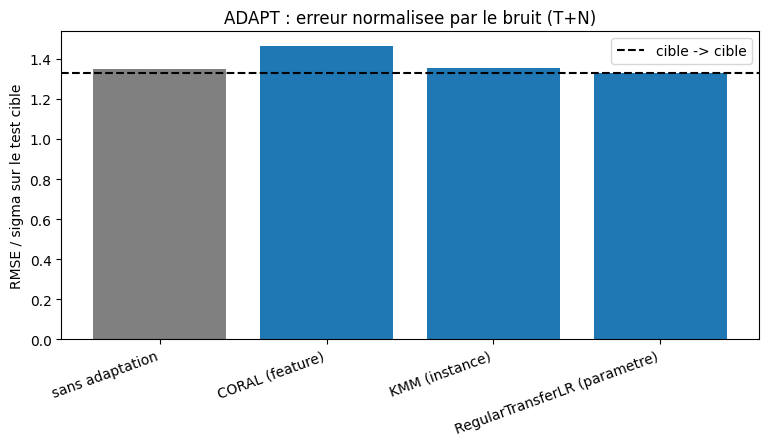

In [120]:
from sklearn.metrics import mean_squared_error

def rmse_sur_sigma(y_vrai, y_pred):
    return float(np.sqrt(mean_squared_error(y_vrai, y_pred)) / sigma_test[ville_cible])

res_adapt_norm = comparer_adapt("forecast", Xrs_train, yrs_train, Xrc_train, yrc_train, Xrc_test, yrc_test, score=rmse_sur_sigma)

for k, v in res_adapt_norm.items():
    print(f"  {k:32s} {round(v, 3)}")

barres_adapt(res_adapt_norm, "ADAPT : erreur normalisee par le bruit (T+N)","RMSE / sigma sur le test cible")

## 18. variance de la serie T+N au fil du temps


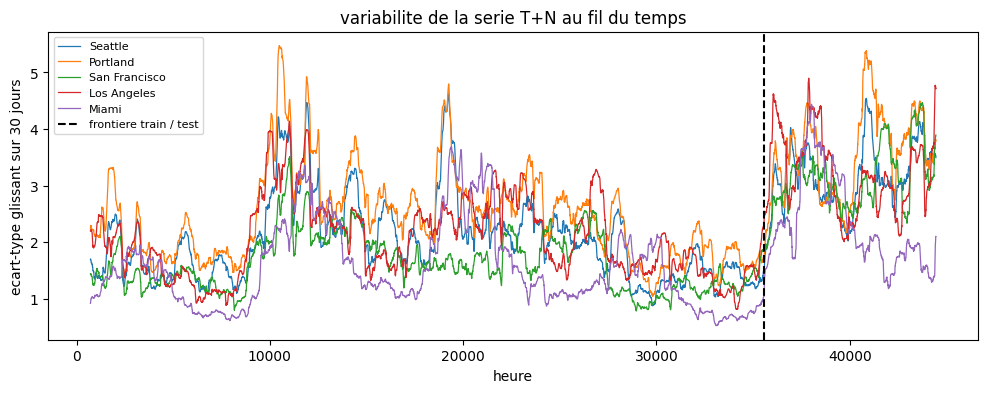

        ville  toute la serie  train  test
      Seattle           2.612  2.314 3.539
     Portland           3.063  2.774 4.014
San Francisco           2.365  1.998 3.401
  Los Angeles           2.873  2.630 3.601
        Miami           2.023  1.848 2.535


In [121]:
fenetre_glissante = 24 * 30

plt.figure(figsize=(12, 4))
lignes = []
for v in source_villes + [ville_cible]:
    z = pd.Series(series_TN[v])
    n_app = int(len(z) * 0.8)
    plt.plot(z.rolling(fenetre_glissante).std(), linewidth=0.9, label=v)
    lignes.append([v, round(float(z.std()), 3), round(float(z[:n_app].std()), 3),
                   round(float(z[n_app:].std()), 3)])

plt.axvline(n_app, color="k", linestyle="--", label="frontiere train / test")
plt.xlabel("heure")
plt.ylabel("ecart-type glissant sur 30 jours")
plt.title("variabilite de la serie T+N au fil du temps")
plt.legend(fontsize=8)
plt.show()

print(pd.DataFrame(lignes, columns=["ville", "toute la serie", "train", "test"]).to_string(index=False))

## 19. le meme graphique avec la MSTL qui voit tout


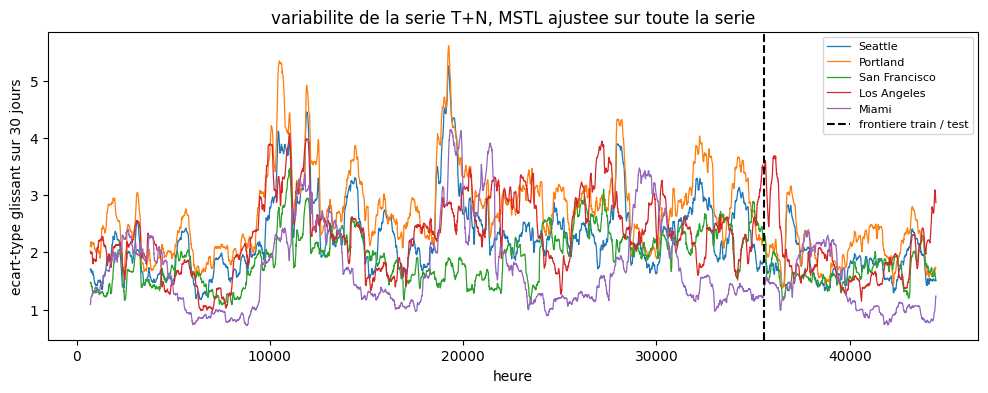

        ville  toute la serie  train  test
      Seattle           2.541  2.648 2.011
     Portland           2.995  3.143 2.309
San Francisco           2.211  2.286 1.777
  Los Angeles           2.830  2.944 2.194
        Miami           2.035  2.107 1.596


In [122]:
plt.figure(figsize=(12, 4))
lignes_fuite = []
for v in source_villes + [ville_cible]:
    z = pd.Series(series_TN_fuite[v])
    n_app = int(len(z) * 0.8)
    plt.plot(z.rolling(fenetre_glissante).std(), linewidth=0.9, label=v)
    lignes_fuite.append([v, round(float(z.std()), 3), round(float(z[:n_app].std()), 3),
                         round(float(z[n_app:].std()), 3)])

plt.axvline(n_app, color="k", linestyle="--", label="frontiere train / test")
plt.xlabel("heure")
plt.ylabel("ecart-type glissant sur 30 jours")
plt.title("variabilite de la serie T+N, MSTL ajustee sur toute la serie")
plt.legend(fontsize=8)
plt.show()

print(pd.DataFrame(lignes_fuite, columns=["ville", "toute la serie", "train", "test"]).to_string(index=False))

## 20. le prolongement de la saisonnalite

serie_TN prolonge la saisonnalite du test en moyennant les quatre annees completes du train

les colonnes err mesurent l'ecart moyen entre la saisonnalite fabriquee et la reference.

        ville  err derniere  err moyenne  T+N derniere  T+N moyenne  T+N avec fuite
      Seattle          2.24         1.92          4.38         3.54            2.01
     Portland          2.60         2.20          5.02         4.01            2.31
San Francisco          2.19         1.94          4.00         3.40            1.78
  Los Angeles          2.46         2.16          4.64         3.60            2.19
        Miami          1.55         1.48          3.23         2.54            1.60


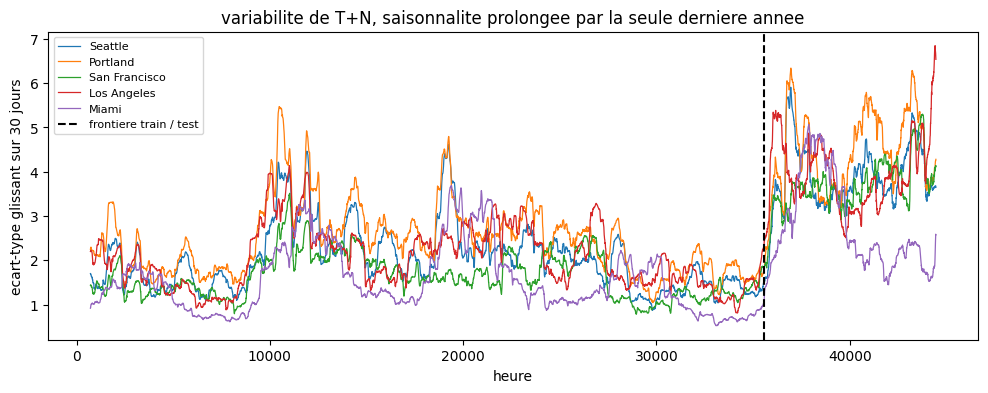

In [123]:
lignes_moy = []
series_TN_derniere = {}
for v in source_villes + [ville_cible]:
    temp = temperature_ville(v)
    n_app = int(len(temp) * 0.8)
    n_test = len(temp) - n_app

    sais_app = temp[:n_app] - series_TN[v][:n_app]
    derniere = np.tile(sais_app[-n_annee:], n_test // n_annee + 1)[:n_test]
    moyenne = temp[n_app:] - series_TN[v][n_app:]
    sais_fuite = temp[n_app:] - series_TN_fuite[v][n_app:]

    series_TN_derniere[v] = np.concatenate([series_TN[v][:n_app], temp[n_app:] - derniere])

    lignes_moy.append([v,
                       round(float(np.mean(np.abs(derniere - sais_fuite))), 2),
                       round(float(np.mean(np.abs(moyenne - sais_fuite))), 2),
                       round(float(np.std(series_TN_derniere[v][n_app:])), 2),
                       round(float(np.std(series_TN[v][n_app:])), 2),
                       round(float(np.std(series_TN_fuite[v][n_app:])), 2)])

print(pd.DataFrame(lignes_moy, columns=["ville", "err derniere", "err moyenne",
                                        "T+N derniere", "T+N moyenne", "T+N avec fuite"]).to_string(index=False))

plt.figure(figsize=(12, 4))
for v in source_villes + [ville_cible]:
    z = pd.Series(series_TN_derniere[v])
    n_app = int(len(z) * 0.8)
    plt.plot(z.rolling(fenetre_glissante).std(), linewidth=0.9, label=v)
plt.axvline(n_app, color="k", linestyle="--", label="frontiere train / test")
plt.xlabel("heure")
plt.ylabel("ecart-type glissant sur 30 jours")
plt.title("variabilite de T+N, saisonnalite prolongee par la seule derniere annee")
plt.legend(fontsize=8)
plt.show()

## 21. erreur sur la serie brute et sur la serie T+N

la serie T+N porte une erreur d'extrapolation de la saisonnalite qui n'existe pas sur la serie brute, puisque celle-ci ne subit aucun retrait. on mesure donc les deux erreurs avec le meme denominateur, le bruit reel du test, pour voir ce que coute la desaisonnalisation.

RMSE / sigma_test, modele partage entraine sur les villes source
        ville  serie brute  serie T+N
      Seattle        1.302      1.323
     Portland        1.280      1.329
San Francisco        1.347      1.372
  Los Angeles        1.048      1.118
        Miami        1.307      1.348


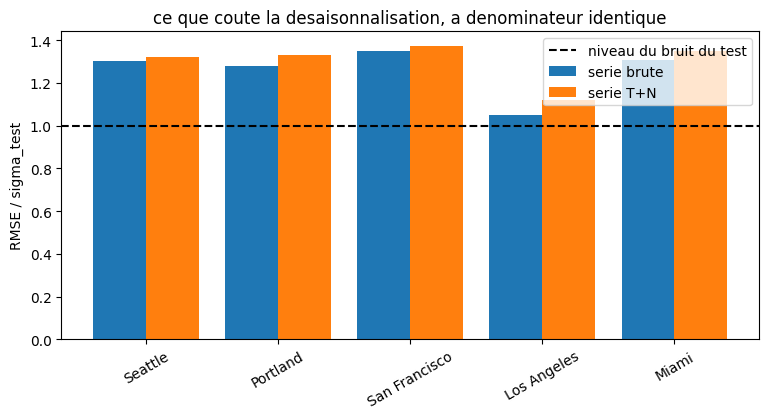

In [124]:
lignes_brut = []
for k, ville in enumerate(source_villes + [ville_cible]):
    if ville == ville_cible:
        mse_brut = predict("forecast", Xs_train, ys_train, Xc_test, yc_test)["mse"]
        mse_tn = predict("forecast", Xrs_train, yrs_train, Xrc_test, yrc_test)["mse"]
    else:
        mse_brut = predict("forecast", Xs_train, ys_train, Xs_test_list[k], ys_test_list[k])["mse"]
        mse_tn = predict("forecast", Xrs_train, yrs_train, Xrs_te_list[k], yrs_te_list[k])["mse"]
    lignes_brut.append([ville,
                        round(float(np.sqrt(mse_brut) / sigma_test[ville]), 3),
                        round(float(np.sqrt(mse_tn) / sigma_test[ville]), 3)])

tab_brut = pd.DataFrame(lignes_brut, columns=["ville", "serie brute", "serie T+N"])
print("RMSE / sigma_test, modele partage entraine sur les villes source")
print(tab_brut.to_string(index=False))

pos = np.arange(len(tab_brut))
plt.figure(figsize=(9, 4))
plt.bar(pos - 0.2, tab_brut["serie brute"], 0.4, label="serie brute")
plt.bar(pos + 0.2, tab_brut["serie T+N"], 0.4, label="serie T+N")
plt.axhline(1.0, color="k", linestyle="--", label="niveau du bruit du test")
plt.xticks(pos, tab_brut["ville"], rotation=30)
plt.ylabel("RMSE / sigma_test")
plt.title("ce que coute la desaisonnalisation, a denominateur identique")
plt.legend()
plt.show()

## 22. le signal de la ville cible


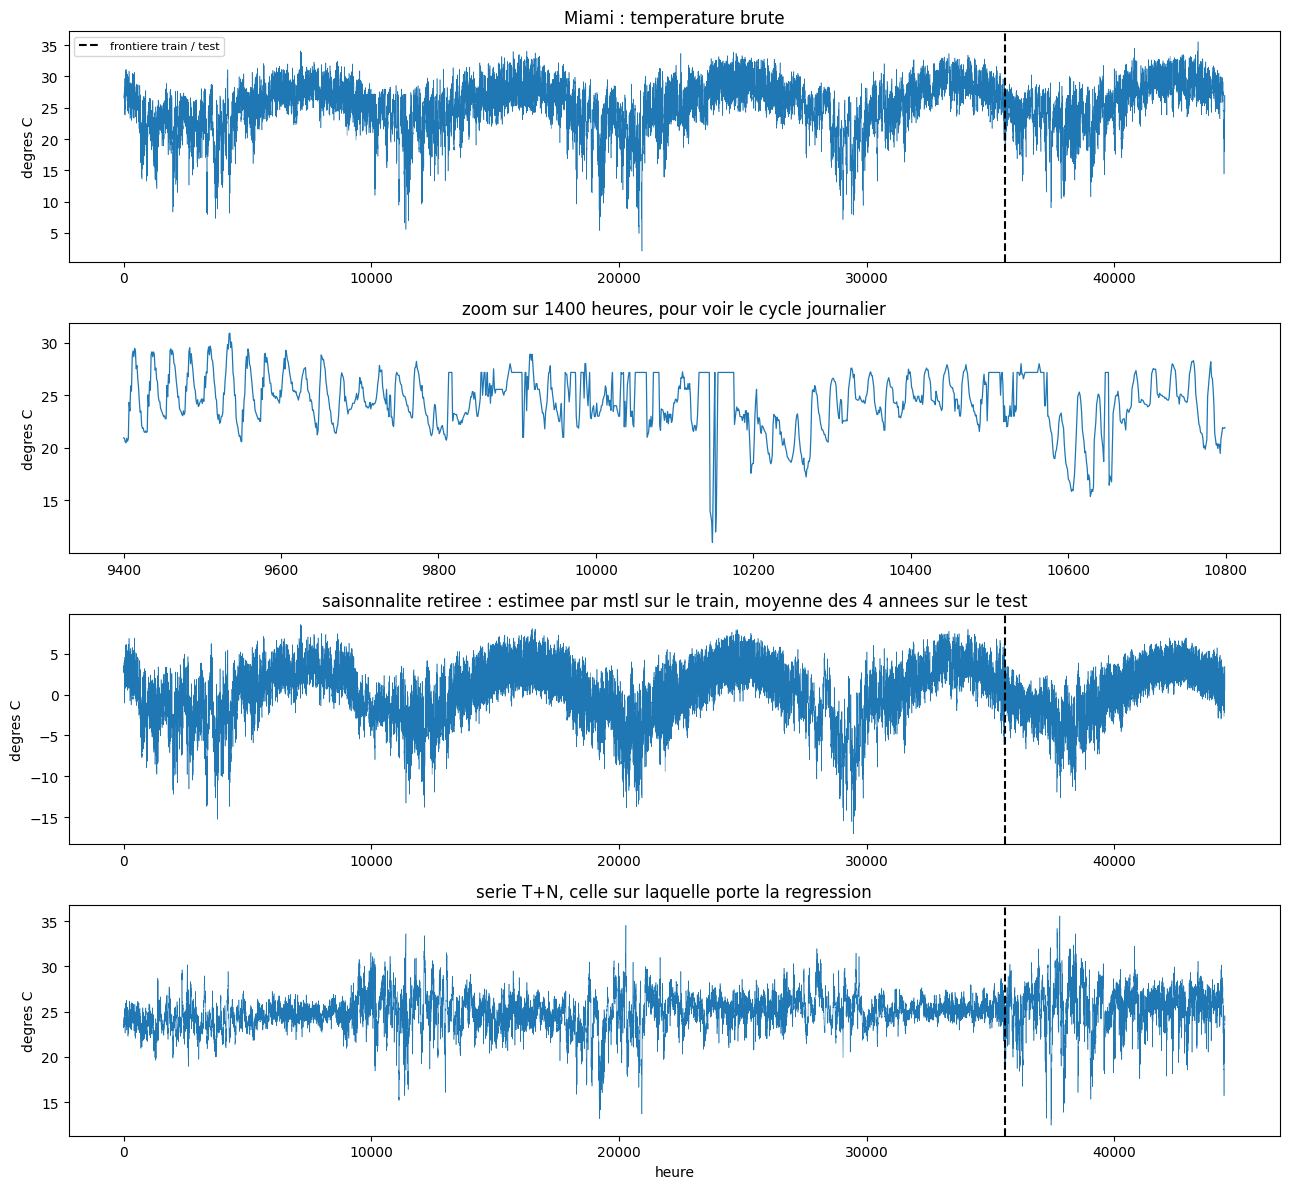

In [125]:
ville_vue = ville_cible

temp_vue = temperature_ville(ville_vue)
n_app_vue = int(len(temp_vue) * 0.8)
res_vue = MSTL(temp_vue[:n_app_vue], periods=(24, 8766), stl_kwargs=dict(seasonal_jump=24, trend_jump=24, low_pass_jump=24)).fit()
sais_vue = np.asarray(res_vue.seasonal).sum(axis=1)
n_test_vue = len(temp_vue) - n_app_vue
n_blocs_vue = n_app_vue // n_annee
blocs_vue = np.stack([sais_vue[n_app_vue - (k + 1) * n_annee: n_app_vue - k * n_annee] for k in range(n_blocs_vue)])
sais_totale = np.concatenate([sais_vue, np.tile(blocs_vue.mean(axis=0), n_test_vue // n_annee + 1)[:n_test_vue]])

fig, ax = plt.subplots(4, 1, figsize=(13, 12))

ax[0].plot(temp_vue, linewidth=0.4)
ax[0].axvline(n_app_vue, color="k", linestyle="--", label="frontiere train / test")
ax[0].set_title(ville_vue + " : temperature brute")
ax[0].set_ylabel("degres C")
ax[0].legend(fontsize=8)

ax[1].plot(range(9400, 10800), temp_vue[9400:10800], linewidth=0.9)
ax[1].set_title("zoom sur 1400 heures, pour voir le cycle journalier")
ax[1].set_ylabel("degres C")

ax[2].plot(sais_totale, linewidth=0.4)
ax[2].axvline(n_app_vue, color="k", linestyle="--")
ax[2].set_title("saisonnalite retiree : estimee par mstl sur le train, moyenne des 4 annees sur le test")
ax[2].set_ylabel("degres C")

ax[3].plot(temp_vue - sais_totale, linewidth=0.4)
ax[3].axvline(n_app_vue, color="k", linestyle="--")
ax[3].set_title("serie T+N, celle sur laquelle porte la regression")
ax[3].set_ylabel("degres C")
ax[3].set_xlabel("heure")

plt.tight_layout()
plt.show()

## 23. arima sur la serie T+N

In [126]:
from statsmodels.tsa.arima.model import ARIMA

memoire = 200

def prevision_arima(res, serie, pas, origines):
    return np.array([float(res.apply(serie[max(0, t - memoire + 1): t + 1], refit=False).forecast(pas)[-1])
                     for t in origines])

z_cible = series_TN[ville_cible]
n_app_cible = int(len(z_cible) * 0.8)
indices_test = np.arange(split_rc, len(Xrc)) + window_size - 1

ordres = [(1, 0, 0), (2, 0, 0), (3, 0, 0), (1, 0, 1), (2, 0, 1), (2, 1, 1)]
lignes_arima = []
for ordre in ordres:
    res = ARIMA(z_cible[:n_app_cible], order=ordre).fit()
    pred = prevision_arima(res, z_cible, horizon_residu, indices_test)
    err = float(np.sqrt(np.mean((pred - yrc_test) ** 2)))
    lignes_arima.append([str(ordre), round(err, 3), round(err / sigma_test[ville_cible], 3), round(res.aic)])

mse_lr = predict("forecast", Xrc_train, yrc_train, Xrc_test, yrc_test)["mse"]
lignes_arima.append(["regression 24 retards", round(float(np.sqrt(mse_lr)), 3),
                     round(float(np.sqrt(mse_lr)) / sigma_test[ville_cible], 3), np.nan])

print("modele appris et evalue sur la cible")
print(pd.DataFrame(lignes_arima, columns=["modele", "RMSE", "RMSE/sigma_test", "AIC"]).to_string(index=False))

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


modele appris et evalue sur la cible
               modele  RMSE  RMSE/sigma_test     AIC
            (1, 0, 0) 2.223            1.398 58428.0
            (2, 0, 0) 2.183            1.373 58239.0
            (3, 0, 0) 2.229            1.402 57993.0
            (1, 0, 1) 2.186            1.375 58268.0
            (2, 0, 1) 2.191            1.378 58031.0
            (2, 1, 1) 2.363            1.486 58732.0
regression 24 retards 2.111            1.328     NaN


### transfert de l'arima d'une ville a l'autre



arima (2, 0, 0) transfere vers Miami
    arima appris sur  RMSE a un pas sur son train  RMSE/sigma_test sur la cible
             Seattle                        0.497                         1.331
            Portland                        0.649                         1.333
       San Francisco                        0.552                         1.364
         Los Angeles                        0.702                         1.337
Miami (modele cible)                        0.549                         1.373


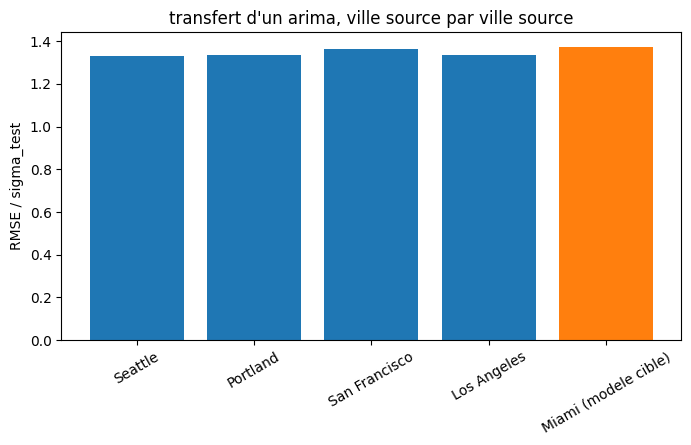

In [127]:
ordre_retenu = (2, 0, 0)

lignes_tr = []
for v in source_villes:
    z_src = series_TN[v]
    res = ARIMA(z_src[:int(len(z_src) * 0.8)], order=ordre_retenu).fit()
    pred = prevision_arima(res, z_cible, horizon_residu, indices_test)
    err = float(np.sqrt(np.mean((pred - yrc_test) ** 2)))
    lignes_tr.append([v, round(float(np.sqrt(np.mean((res.resid[100:]) ** 2))), 3),
                      round(err / sigma_test[ville_cible], 3)])

res_c = ARIMA(z_cible[:n_app_cible], order=ordre_retenu).fit()
pred_c = prevision_arima(res_c, z_cible, horizon_residu, indices_test)
lignes_tr.append([ville_cible + " (modele cible)", round(float(np.sqrt(np.mean((res_c.resid[100:]) ** 2))), 3),
                  round(float(np.sqrt(np.mean((pred_c - yrc_test) ** 2))) / sigma_test[ville_cible], 3)])

tab_tr = pd.DataFrame(lignes_tr, columns=["arima appris sur", "RMSE a un pas sur son train", "RMSE/sigma_test sur la cible"])
print(f"arima {ordre_retenu} transfere vers {ville_cible}")
print(tab_tr.to_string(index=False))

plt.figure(figsize=(8, 4))
couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
plt.bar(tab_tr["arima appris sur"], tab_tr["RMSE/sigma_test sur la cible"], color=couleurs)
plt.ylabel("RMSE / sigma_test")
plt.title("transfert d'un arima, ville source par ville source")
plt.xticks(rotation=30)
plt.show()

## 24. la fraction du niveau restituee par le modele


In [131]:
from sklearn.linear_model import LinearRegression

series_non_centrees = {v: series_TN[v] + moyenne_ville[v] for v in source_villes + [ville_cible]}

Xn_list, yn_list = [], []
for v in source_villes:
    X, y = sliding_window(series_non_centrees[v], window_size, horizon_residu)
    s = int(len(X) * 0.8)
    Xn_list.append(X[:s]); yn_list.append(y[:s])
Xn_train = np.vstack(Xn_list); yn_train = np.concatenate(yn_list)

Xnc, ync = sliding_window(series_non_centrees[ville_cible], window_size, horizon_residu)
sc = int(len(Xnc) * 0.8)

modele_non_centre = LinearRegression().fit(Xn_train, yn_train)
somme = float(modele_non_centre.coef_.sum())
print("sans centrage")
print("  somme des coefficients :", round(somme, 4))
print("  ordonnee a l'origine   :", round(float(modele_non_centre.intercept_), 4))

niveau_source = float(yn_train.mean())
niveau_cible = float(series_non_centrees[ville_cible][:int(len(series_non_centrees[ville_cible]) * 0.8)].mean())
ecart = niveau_cible - niveau_source
biais_mesure = float(np.mean(modele_non_centre.predict(Xnc[sc:]) - ync[sc:]))
print("  niveau moyen source    :", round(niveau_source, 3))
print("  niveau moyen cible     :", round(niveau_cible, 3))
print("  ecart de niveau        :", round(ecart, 3))
print("  biais attendu          :", round(-(1 - somme) * ecart, 3))
print("  biais mesure           :", round(biais_mesure, 3))

modele_centre = LinearRegression().fit(Xrs_train, yrs_train)
print()
print("avec centrage")
print("  somme des coefficients :", round(float(modele_centre.coef_.sum()), 4))
print("  biais mesure           :", round(float(np.mean(modele_centre.predict(Xrc_test) - yrc_test)), 3))

sans centrage
  somme des coefficients : 0.8823
  ordonnee a l'origine   : 1.6303
  niveau moyen source    : 13.869
  niveau moyen cible     : 24.867
  ecart de niveau        : 10.998
  biais attendu          : -1.294
  biais mesure           : -1.37

avec centrage
  somme des coefficients : 0.736
  biais mesure           : -0.177


In [129]:
res_verif = ARIMA(z_cible[:n_app_cible], order=(2, 0, 0)).fit()
controle = indices_test[:20]

tronque = prevision_arima(res_verif, z_cible, horizon_residu, controle)
complet = np.array([float(res_verif.apply(z_cible[:t + 1], refit=False).forecast(horizon_residu)[-1])
                    for t in controle])

print(f"prevision a {horizon_residu} pas depuis les 20 premieres origines du test")
print(f"  prefixe tronque a {memoire} points contre prefixe complet")
print(f"  ecart maximal : {np.abs(tronque - complet).max():.2e}")

prevision a 24 pas depuis les 20 premieres origines du test
  prefixe tronque a 200 points contre prefixe complet
  ecart maximal : 0.00e+00
